In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pylab as plt

plt.rcParams["font.family"] = "AppleGothic"

df = sns.load_dataset("diamonds")
print(df.shape)
print(df.head(5))
print(df.info())
print(df.isnull().sum())

# null 값은 없습니다. x, y, z 컬럼의 값이 0인 데이터가 있습니다.
print(df.loc[df['x'] == 0, ].head(5))

df.describe().round(2)

(53940, 10)
   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float

,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


In [2]:
x_zero_cnt = len(df.loc[df['x'] == 0])
y_zero_cnt = len(df.loc[df['y'] == 0])
z_zero_cnt = len(df.loc[df['z'] == 0])
print(f"값이 0인 x {x_zero_cnt}개 | y {y_zero_cnt}개 | z {z_zero_cnt}개")
print(df.loc[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0), ])

bad_cond = (df['y'] > 20) | (df['z'] > 20)
clean = df.loc[~bad_cond, ].copy()
# y 나 z 가 20mm 를 넘는 행을 찾아 직접 본다. 왜 이상한 값이라고 판단할 수 있는지 적는다.
# 이 답은 아직 모르겠습니다.
clean
# q1 = df['y'].quantile(0.25)
# q3 = df['y'].quantile(0.75)

# IQR = q3 + 1.5 * (q3 - q1)
# IQR

값이 0인 x 8개 | y 7개 | z 20개
       carat        cut color clarity  depth  table  price     x     y    z
2207    1.00    Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01    Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10    Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01    Premium     F     SI2   59.2   58.0   3837  6.50  6.47  0.0
10167   1.50       Good     G      I1   64.0   61.0   4731  7.15  7.04  0.0
11182   1.07      Ideal     F     SI2   61.6   56.0   4954  0.00  6.62  0.0
11963   1.00  Very Good     H     VS2   63.3   53.0   5139  0.00  0.00  0.0
13601   1.15      Ideal     G     VS2   59.2   56.0   5564  6.88  6.83  0.0
15951   1.14       Fair     G     VS1   57.5   67.0   6381  0.00  0.00  0.0
24394   2.18    Premium     H     SI2   59.4   61.0  12631  8.49  8.45  0.0
24520   1.56      Ideal     G     VS2   62.2   54.0  12800  0.00  0.00  0.0
26123   2.25    Premium     I     SI1   61.3   58.0  15397  8.

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


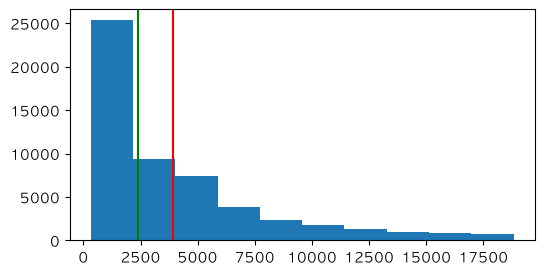

In [3]:
fig, ax = plt.subplots(figsize=(6,3))

ax.hist(df['price'])
ax.axvline(df['price'].mean(), color='red')
ax.axvline(df['price'].median(), color='green')
plt.show()


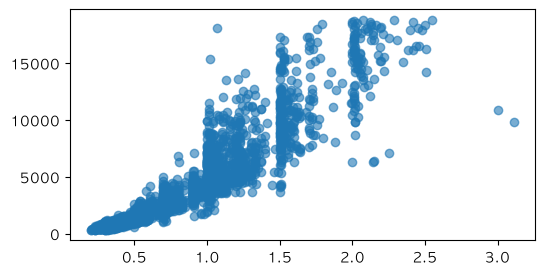

In [4]:
fig, ax = plt.subplots(figsize=(6,3))

df_scatter = df.sample(3000)
ax.scatter(df_scatter['carat'], df_scatter['price'], alpha=0.6)
plt.show()

In [5]:
# corr_score = df['carat'].corr(df['price'])
# print(corr_score.round(2))


# df['corr_score'] = df['carat'].corr(df['price'].round(2))
# df.sort_values('corr_score')

df_corr_score = df.corr(numeric_only=True)['price'].sort_values(ascending=False)[1:]
print(df_corr_score)

carat    0.921591
x        0.884435
y        0.865421
z        0.861249
table    0.127134
depth   -0.010647
Name: price, dtype: float64


기울기 w = 7756.43
절편 b = -2256.36
무게가 1 캐럿 늘면 가격이 7756.43 원 오른다.

예측결과:
   carat  pred_price
0   0.25      -320.0
1   0.50      1620.0
2   1.00      5500.0
3   2.00     13260.0
이상한 점: 음수가 나옴.



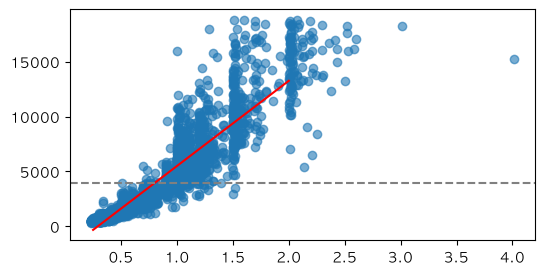

In [ ]:
from sklearn.linear_model import LinearRegression

X = df[["carat"]]
y = df["price"]

# 선형 회귀 모델 만들기
model = LinearRegression()
# 학습 : X(입력값), y(정답)
model.fit(X, y)

print(f"기울기 w = {model.coef_[0].round(2)}")
print(f"절편 b = {model.intercept_.round(2)}")
print('무게가 1 캐럿 늘면 가격이 7756.43 원 오른다.')

new = pd.DataFrame({"carat":[0.25, 0.5, 1.0, 2.0]})
new['pred_price'] = model.predict(new).round(-1)
print(f"\n예측결과:\n{new}")
print('이상한 점: 음수가 나옴.\n')

fig, ax = plt.subplots(figsize=(6,3))

df_scatter = df.sample(3000)
ax.scatter(df_scatter['carat'], df_scatter['price'], alpha=0.6)
ax.plot(new['carat'], new['pred_price'], color='r')

ax.axhline(df_scatter['price'].mean(), color='gray', linestyle='--')
plt.show()

In [14]:
df.info()

X = df[["depth"]]
y = df["price"]
model.fit(X, y)
print(f"기울기 w = {model.coef_[0].round(2)}")
print(f"절편 b = {model.intercept_.round(2)}")

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
기울기 w = -29.65
절편 b = 5763.67
